In [3]:
import cv2
import glob
import numpy as np
from tqdm import tqdm
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
from collections import Counter
import random
import imageio
from IPython.display import Image
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau
import os

In [4]:
def crop_center_square(img):
    h, w = img.shape[:2]
    square_w = min(h, w)

    start_x = w // 2 - square_w // 2
    end_x = start_x + square_w

    start_y = h // 2 - square_w // 2
    end_y = start_y + square_w

    result = img[start_y:end_y, start_x:end_x]

    return result

In [5]:
def preprocess_hand(frame):
    # 转换为 YCrCb 颜色空间
    ycrcb_frame = cv2.cvtColor(frame, cv2.COLOR_BGR2YCrCb)
    # 定义肤色范围
    lower_skin = np.array([0, 133, 77], dtype=np.uint8)
    upper_skin = np.array([255, 173, 127], dtype=np.uint8)
    # 肤色分割
    skin_mask = cv2.inRange(ycrcb_frame, lower_skin, upper_skin)

    # 形态学处理：开运算去噪，闭运算填充空洞
    kernel = np.ones((3, 3), np.uint8)
    skin_mask = cv2.morphologyEx(skin_mask, cv2.MORPH_OPEN, kernel)
    skin_mask = cv2.morphologyEx(skin_mask, cv2.MORPH_CLOSE, kernel)

    # 将肤色区域与原图像融合
    result = cv2.bitwise_and(frame, frame, mask=skin_mask)
    return result

In [6]:
def load_video(file_name):
    cap = cv2.VideoCapture(file_name)
    # 每隔多少帧抽取一次
    frame_interval = 4
    frames = []
    count = 0
    while True:
        ret, frame = cap.read()
        if not ret:
            break

        # 每隔frame_interval帧保存一次
        if count % frame_interval == 0:
            # 中心裁剪
            frame = crop_center_square(frame)
            # 肤色检测和形态学处理
            frame = preprocess_hand(frame)
            # 缩放
            frame = cv2.resize(frame, (IMG_SIZE, IMG_SIZE))
            # BGR -> RGB  [0,1,2] -> [2,1,0]
            frame = frame[:, :, [2, 1, 0]]
            frames.append(frame)
        count += 1

    return np.array(frames)

In [7]:
def get_feature_extractor():
    feature_extractor = keras.applications.inception_resnet_v2.InceptionResNetV2(
        weights='imagenet',
        include_top=False,
        pooling='avg',
        input_shape=(IMG_SIZE, IMG_SIZE, 3)
    )

    preprocess_input = keras.applications.inception_resnet_v2.preprocess_input

    inputs = keras.Input((IMG_SIZE, IMG_SIZE, 3))
    preprocessed = preprocess_input(inputs)
    outputs = feature_extractor(preprocessed)

    model = keras.Model(inputs, outputs, name='feature_extractor')

    return model

In [8]:
def load_data(videos, labels):
    video_features = []

    for video in tqdm(videos):
        frames = load_video(video)
        counts = len(frames)
        # 如果帧数小于MAX_SEQUENCE_LENGTH
        if counts < MAX_SEQUENCE_LENGTH:
            # 补白
            diff = MAX_SEQUENCE_LENGTH - counts
            # 创建全0的numpy数组
            padding = np.zeros((diff, IMG_SIZE, IMG_SIZE, 3))
            # 数组拼接
            frames = np.concatenate((frames, padding))
        # 获取前MAX_SEQUENCE_LENGTH帧画面
        frames = frames[:MAX_SEQUENCE_LENGTH, :]
        # 批量提取特征
        video_feature = feature_extractor.predict(frames)
        video_features.append(video_feature)

    return np.array(video_features), np.array(labels)

In [9]:
class PositionalEmbedding(layers.Layer):
    def __init__(self, seq_length, output_dim):
        super().__init__()
        # 构造从0~MAX_SEQUENCE_LENGTH的列表
        self.positions = tf.range(0, limit=MAX_SEQUENCE_LENGTH)
        self.positional_embedding = layers.Embedding(input_dim=seq_length, output_dim=output_dim)

    def call(self, x):
        # 位置编码
        positions_embedding = self.positional_embedding(self.positions)
        # 输入相加
        return x + positions_embedding

In [10]:
class TransformerEncoder(layers.Layer):
    def __init__(self, num_heads, embed_dim):
        super().__init__()
        self.p_embedding = PositionalEmbedding(MAX_SEQUENCE_LENGTH, NUM_FEATURES)
        self.attention = layers.MultiHeadAttention(num_heads=num_heads, key_dim=embed_dim, dropout=0.1)
        self.layernorm = layers.LayerNormalization()

    def call(self, x):
        # positional embedding
        positional_embedding = self.p_embedding(x)
        # self attention
        attention_out = self.attention(
            query=positional_embedding,
            value=positional_embedding,
            key=positional_embedding,
            attention_mask=None
        )
        # layer norm with residual connection
        output = self.layernorm(positional_embedding + attention_out)
        return output

In [11]:
def video_cls_model(class_vocab):
    # 类别数量
    classes_num = len(class_vocab)
    # 定义模型
    model = keras.Sequential([
        layers.InputLayer(input_shape=(MAX_SEQUENCE_LENGTH, NUM_FEATURES)),
        TransformerEncoder(2, NUM_FEATURES),
        layers.GlobalMaxPooling1D(),
        layers.Dropout(0.1),
        layers.Dense(classes_num, activation="softmax")
    ])
    # 编译模型
    model.compile(optimizer=keras.optimizers.Adam(1e-5),
                  loss=keras.losses.SparseCategoricalCrossentropy(from_logits=False),
                  metrics=['accuracy']
                  )
    return model

In [12]:
def getVideoFeat(frames):
    frames_count = len(frames)

    # 如果帧数小于MAX_SEQUENCE_LENGTH
    if frames_count < MAX_SEQUENCE_LENGTH:
        # 补白
        diff = MAX_SEQUENCE_LENGTH - frames_count
        # 创建全0的numpy数组
        padding = np.zeros((diff, IMG_SIZE, IMG_SIZE, 3))
        # 数组拼接
        frames = np.concatenate((frames, padding))

    # 取前MAX_SEQ_LENGTH帧
    frames = frames[:MAX_SEQUENCE_LENGTH, :]
    # 计算视频特征 N, 1536
    video_feat = feature_extractor.predict(frames)

    return video_feat

In [13]:
def testVideo():
    test_file = random.sample(videos, 1)[0]
    label = test_file.split('_')[-2]

    print('文件名:{}'.format(test_file))
    print('真实类别:{}'.format(label_to_name.get(int(label))))

    # 读取视频每一帧
    frames = load_video(test_file)
    # 挑选前帧MAX_SEQUENCE_LENGTH显示
    frames = frames[:MAX_SEQUENCE_LENGTH].astype(np.uint8)

    # 检查 frames 的形状，确保符合要求
    if frames.ndim == 4 and frames.shape[3] in [1, 3]:
        # 保存为GIF
        imageio.mimsave('animation.gif', frames, duration=1)
        # 获取特征
        feat = getVideoFeat(frames)
        # 模型推理
        prob = model.predict(tf.expand_dims(feat, axis=0))[0]

        print('预测类别：')
        for i in np.argsort(prob)[::-1][:5]:
            print('{}: {}%'.format(label_to_name[i], round(prob[i] * 100, 2)))

    else:
        print("帧数据的形状不符合要求，无法保存为GIF。")

    #return display(Image(open('animation.gif', 'rb').read()))

Tensorflow version: 2.13.0
GPU available: []
[1, 5, 0, 4, 5, 6, 0, 3, 1, 0, 1, 0, 2, 4, 6, 5, 1, 5, 5, 0, 2, 4, 0, 6, 0, 3, 4, 0, 0, 4, 3, 2, 3, 6, 2, 4, 6, 1, 2, 0, 3, 1, 0, 5, 4, 0, 6, 5, 5, 0, 4, 0, 5, 6, 0, 2, 0, 3, 6, 0, 4, 1, 0, 3, 0, 2, 1, 3, 1, 2, 0, 3, 0, 2, 3, 4, 3, 0, 4, 0, 0, 0, 3, 6, 1, 0, 6, 0, 1, 5, 2, 5, 6, 0, 0, 0, 0, 6, 2, 4, 2, 5, 2, 0, 1, 6, 0, 0]
Counter({0: 34, 6: 13, 2: 13, 1: 12, 5: 12, 4: 12, 3: 12})


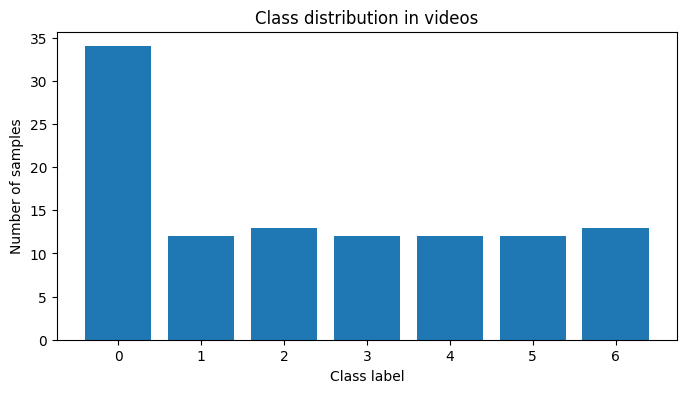

上滑
帧数据的形状不符合要求，无法保存为GIF。
Model: "feature_extractor"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 input_3 (InputLayer)        [(None, 299, 299, 3)]     0         
                                                                 
 tf.math.truediv (TFOpLambd  (None, 299, 299, 3)       0         
 a)                                                              
                                                                 
 tf.math.subtract (TFOpLamb  (None, 299, 299, 3)       0         
 da)                                                             
                                                                 
 inception_resnet_v2 (Funct  (None, 1536)              54336736  
 ional)                                                          
                                                                 
Total params: 54336736 (207.28 MB)
Trainable params: 54276192 (207.05 MB)
Non-trainable pa

  0%|          | 0/10 [00:00<?, ?it/s]


ValueError: all the input arrays must have same number of dimensions, but the array at index 0 has 1 dimension(s) and the array at index 1 has 4 dimension(s)

In [15]:
if __name__ == '__main__':
    print('Tensorflow version: {}'.format(tf.__version__))
    print('GPU available: {}'.format(tf.config.list_physical_devices('GPU')))

    MAX_SEQUENCE_LENGTH = 40
    IMG_SIZE = 299
    NUM_FEATURES = 1536

    # 获取当前工作目录
    current_dir = os.getcwd()
    # 视频文件所在文件夹路径
    cv_folder_path = os.path.join(current_dir, 'cv')
    # 列出 cv 文件夹下所有视频文件
    videos = [f for f in os.listdir(cv_folder_path) if f.endswith('.mp4')]
    np.random.shuffle(videos)
    labels = [int(video.split('_')[-2]) for video in videos]
    print(labels)

    # 显示数据分布情况
    counts = Counter(labels)
    print(counts)

    plt.figure(figsize=(8, 4))
    plt.bar(counts.keys(), counts.values())
    plt.xlabel('Class label')
    plt.ylabel('Number of samples')
    plt.title('Class distribution in videos')
    plt.show()

    # 显示视频
    label_to_name = {0: '无效手势', 1: '上滑', 2: '下滑', 3: '左滑', 4: '右滑', 5: '打开', 6: '关闭', 7: '放大', 8: '缩小'}
    print(label_to_name.get(labels[0]))

    frames = load_video(videos[0])
    frames = frames[:MAX_SEQUENCE_LENGTH].astype(np.uint8)

    # 检查 frames 的形状，确保符合要求
    if frames.ndim == 4 and frames.shape[3] in [1, 3]:
        imageio.mimsave('test.gif', frames, duration=1)
        print('mim save test.git')
    else:
        print("帧数据的形状不符合要求，无法保存为GIF。")

    feature_extractor = get_feature_extractor()
    feature_extractor.summary()

    # 只对前10个视频进行处理
    video_features, classes = load_data(videos[:10], labels[:10])
    video_features.shape, classes.shape
    print(video_features.shape)
    print(classes.shape)

    # Dataset
    batch_size = 16

    dataset = tf.data.Dataset.from_tensor_slices((video_features, classes))

    dataset = dataset.shuffle(len(videos[:10]))

    test_count = int(len(videos[:10]) * 0.2)
    train_count = len(videos[:10]) - test_count

    dataset_train = dataset.skip(test_count).cache().repeat()
    dataset_test = dataset.take(test_count).cache().repeat()

    train_dataset = dataset_train.shuffle(train_count).batch(batch_size)
    test_dataset = dataset_test.shuffle(test_count).batch(batch_size)

    print(train_dataset)
    print(train_count)
    print(test_dataset)
    print(test_count)

    # 模型实例化
    model = video_cls_model(np.unique(labels[:10]))
    # 打印模型结构
    model.summary()

    # 保存检查点
    checkpoint = ModelCheckpoint(filepath='best.h5', monitor='val_loss', save_weights_only=True, save_best_only=True,
                                 verbose=1, mode='min')
    # 提前终止
    earlyStopping = EarlyStopping(monitor='loss', patience=50, mode='min', baseline=None)
    # 减少learning rate
    rlp = ReduceLROnPlateau(monitor='loss', factor=0.7, patience=30, min_lr=1e-15, mode='min', verbose=1)

    # 开始训练
    history = model.fit(train_dataset,
                        epochs=1000,
                        steps_per_epoch=train_count // batch_size,
                        validation_steps=test_count // batch_size,
                        validation_data=test_dataset,
                        callbacks=[checkpoint, earlyStopping, rlp])
    # 绘制结果
    plt.plot(history.epoch, history.history['loss'], 'r', label='loss')
    plt.plot(history.epoch, history.history['val_loss'], 'g--', label='val_loss')
    plt.title('VIT Model')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.legend()

    plt.plot(history.epoch, history.history['accuracy'], 'r', label='acc')
    plt.plot(history.epoch, history.history['val_accuracy'], 'g--', label='val_acc')
    plt.title('VIT Model')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy')
    plt.legend()

    # 加载训练最优权重
    model.load_weights('best.h5')

    # 模型评估
    model.evaluate(dataset.batch(batch_size))

    # 保存模型
    model.save('saved_model')
    print('save model')
    # 手势识别
    # 加载模型
    model = tf.keras.models.load_model('saved_model')
    # 类别标签
    label_to_name = {0: '无效手势', 1: '上滑', 2: '下滑', 3: '左滑', 4: '右滑', 5: '打开', 6: '关闭', 7: '放大', 8: '缩小'}

    # 视频推理
    for i in range(20):
        testVideo()